**Question 1**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV, StratifiedKFold)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

cancer = load_breast_cancer()

X = pd.DataFrame(cancer['data'], columns=cancer['feature_names'])
y = np.ravel(pd.DataFrame(cancer['target'], columns=['Cancer']))
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

names = ['Decision Tree', 'Random Forest', 'SVC']
classifiers = [DecisionTreeClassifier(random_state=0), RandomForestClassifier(random_state=0), SVC(random_state=0)]

test_error = {}
for name, clf in zip(names, classifiers):
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    test_error[name] = 1 - acc
    print('{:15s} accuracy={:.4f}  testing error={:.4f}'.format(name, acc, 1 - acc))

# select the model with the minimum testing error
best_q1 = min(test_error, key=test_error.get)
print('\nBest model (minimum testing error):', best_q1)

# print the classification report of the best model in Q1
best_clf = classifiers[names.index(best_q1)]
print(classification_report(y_test, best_clf.predict(X_test), target_names=['malignant', 'benign']))

Decision Tree   accuracy=0.8811  testing error=0.1189
Random Forest   accuracy=0.9720  testing error=0.0280
SVC             accuracy=0.9371  testing error=0.0629

Best model (minimum testing error): Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        53
      benign       0.99      0.97      0.98        90

    accuracy                           0.97       143
   macro avg       0.97      0.97      0.97       143
weighted avg       0.97      0.97      0.97       143



I train the three models with their default parameters on the same training set and test them on the same test set. For each model we report the testing error, defined as **testing error = 1-accurancy**, The model with the smallest testing error is the best one under the default settings.

With default settings, the Random Forest has the smallest testing error (about 0.028), followed by SVC and then the single Decision Tree. Averaging many trees makes the random forest much more stable than one decision tree. (random_state=0 only fixes the random seed; all other hyperparameters stay at their defaults.)

**Question 2**

In Q1 every model used its default parameters. Now we tune the hyperparameters of each model and compare them. To avoid an optimistic (biased) score, we use nested cross-validation, which has two loops, Outer loop and Inner loop.

The inner search is repeated fresh inside every outer fold, so the test data never leaks into model selection.

In [3]:
# every model is put in a pipeline: scale features first, then classify.
# scaling is needed by SVC; it doesnt change tree models.
def make_pipe(model):
    return Pipeline([('scaler', StandardScaler()), ('clf', model)])

# hyperparameter options for each model. The 'clf__' prefix points to the pipeline step.
grid_specs = {
    'Decision Tree': (make_pipe(DecisionTreeClassifier(random_state=0)), {'clf__max_depth': [3, 5, 8, None], 'clf__min_samples_leaf': [1, 2, 5]}),
    'Random Forest': (make_pipe(RandomForestClassifier(random_state=0)), {'clf__n_estimators': [50, 100], 'clf__max_depth': [4, 6, None], 'clf__min_samples_leaf': [1, 2]}),
    'SVC': (make_pipe(SVC()), {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': [0.1, 0.01, 0.001, 'scale'], 'clf__kernel': ['rbf']}),
}

# outer folds used to evaluate the tuned models
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

nested_score = {}
best_params = {}
for name, (pipe, param_grid) in grid_specs.items():
    # inner loop: grid search on the outer training fold
    inner_search = GridSearchCV(pipe, param_grid, cv=3, scoring='accuracy')
    # outer loop: score the tuned model on the held-out outer fold
    outer_scores = cross_val_score(inner_search, X, y, cv=outer_cv, scoring='accuracy')
    nested_score[name] = outer_scores.mean()

    # also fit on all data to report the optimal hyperparameters
    full_search = GridSearchCV(pipe, param_grid, cv=3, scoring='accuracy').fit(X, y)
    best_params[name] = full_search.best_params_

    print('{:15s} nested CV scores = {}  mean = {:.4f}'.format(name, np.round(outer_scores, 4), outer_scores.mean()))
    print('               optimal hyperparameters:', full_search.best_params_, '\n')

Decision Tree   nested CV scores = [0.886  0.9474 0.9298 0.9211 0.9558]  mean = 0.9280
               optimal hyperparameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 2} 

Random Forest   nested CV scores = [0.9386 0.9649 0.9474 0.9474 0.9823]  mean = 0.9561
               optimal hyperparameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 50} 

SVC             nested CV scores = [0.9561 0.9737 0.9825 0.9912 0.9735]  mean = 0.9754
               optimal hyperparameters: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'} 



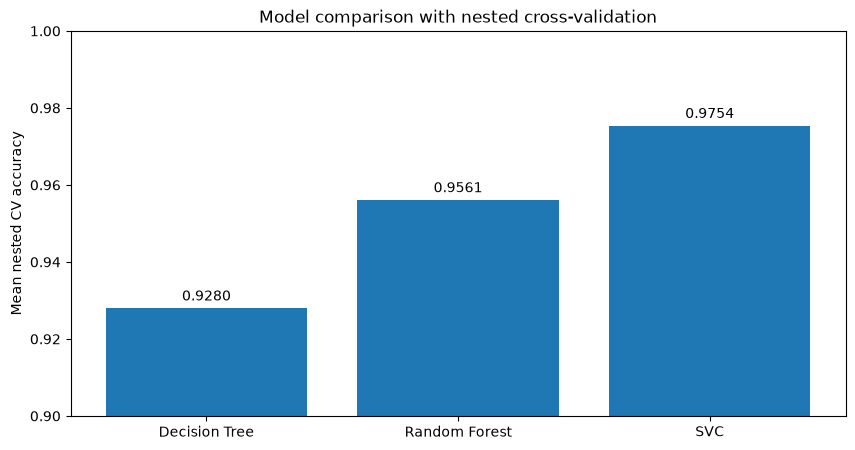

Best model after tuning: SVC
Optimal hyperparameters: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}


In [4]:
plt.figure(figsize=(10, 5))
plt.bar(list(nested_score.keys()), list(nested_score.values()))
plt.ylim(0.9, 1.0)
plt.ylabel('Mean nested CV accuracy')
plt.title('Model comparison with nested cross-validation')
for i, v in enumerate(nested_score.values()):
    plt.text(i, v + 0.002, '{:.4f}'.format(v), ha='center')
plt.show()

best_q2 = max(nested_score, key=nested_score.get)
print('Best model after tuning:', best_q2)
print('Optimal hyperparameters:', best_params[best_q2])

After hyperparameter tuning, SVC achieves the highest mean nested CV accuracy (about 0.975), with optimal parameters close to C=1, gamma='scale', kernel='rbf'. It is followed by Random Forest and then the Decision Tree.

Note that the nested CV score is slightly lower than a score obtained by tuning and testing on the same data. This is expected: nested CV honestly measures the whole tuning process, which is exactly why we use it to compare models.

**Question 3**

All four methods use the same nested CV folds, with classifier parameters retuned inside each outer training fold.

In [5]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Retune the Q2 model family within each outer training fold.
q3_base = clone(grid_specs[best_q2][0])
q3_grid = grid_specs[best_q2][1]

def q3_pipeline(extra_step=None, balanced=False):
    classifier = clone(q3_base.named_steps['clf'])
    if balanced:
        classifier.set_params(class_weight='balanced')
    steps = [('scaler', StandardScaler())]
    if extra_step is not None:
        steps.append(extra_step)
    steps.append(('clf', classifier))
    return Pipeline(steps)

candidates = {
    'Baseline': q3_pipeline(),
    'SelectKBest (k=10)': q3_pipeline(('select', SelectKBest(f_classif, k=10))),
    'PCA (n=10)': q3_pipeline(('pca', PCA(n_components=10, svd_solver='full'))),
    'Balanced weights': q3_pipeline(balanced=True),
}

# Compare fixed k=10 / n_components=10 settings on identical folds.
outer_splits = list(outer_cv.split(X, y))
q3_rows = []
q3_fold_results = {}
q3_predictions = {}

for name, pipe in candidates.items():
    fold_rows = []
    oof_predictions = np.full(len(y), -1, dtype=int)
    for fold, (train_index, valid_index) in enumerate(outer_splits, start=1):
        search = GridSearchCV(clone(pipe), q3_grid, cv=3, scoring='accuracy')
        search.fit(X.iloc[train_index], y[train_index])
        predictions = search.predict(X.iloc[valid_index])
        actual = y[valid_index]
        oof_predictions[valid_index] = predictions
        fold_rows.append({
            'Fold': fold,
            'Accuracy': accuracy_score(actual, predictions),
            'Malignant precision': precision_score(actual, predictions, pos_label=0, zero_division=0),
            'Malignant recall': recall_score(actual, predictions, pos_label=0),
            'Malignant F1': f1_score(actual, predictions, pos_label=0),
            'Benign recall': recall_score(actual, predictions, pos_label=1),
            'Macro F1': f1_score(actual, predictions, average='macro'),
        })
    fold_table = pd.DataFrame(fold_rows).set_index('Fold')
    q3_fold_results[name] = fold_table
    q3_predictions[name] = oof_predictions
    row = {'Method': name, 'Accuracy': fold_table['Accuracy'].mean(),
           'Accuracy SD': fold_table['Accuracy'].std(ddof=0)}
    for metric in ['Malignant precision', 'Malignant recall', 'Malignant F1', 'Benign recall', 'Macro F1']:
        row[metric] = fold_table[metric].mean()
    q3_rows.append(row)
    print(name, 'fold accuracies:', fold_table['Accuracy'].round(4).tolist(), flush=True)

q3_results = pd.DataFrame(q3_rows).set_index('Method')
print('\nMean outer-fold metrics (accuracy SD describes fold variation):')
print(q3_results.round(4).to_string())

Baseline fold accuracies: [0.9561, 0.9737, 0.9825, 0.9912, 0.9735]
SelectKBest (k=10) fold accuracies: [0.9386, 0.9649, 0.9386, 0.9561, 0.9912]
PCA (n=10) fold accuracies: [0.9561, 1.0, 0.9737, 0.9912, 0.9912]
Balanced weights fold accuracies: [0.9561, 0.9737, 0.9912, 0.9825, 0.9735]

Mean outer-fold metrics (accuracy SD describes fold variation):
                    Accuracy  Accuracy SD  Malignant precision  Malignant recall  Malignant F1  Benign recall  Macro F1
Method                                                                                                                 
Baseline              0.9754       0.0116               0.9765            0.9576        0.9668         0.9859    0.9736
SelectKBest (k=10)    0.9579       0.0195               0.9679            0.9196        0.9413         0.9803    0.9542
PCA (n=10)            0.9824       0.0157               0.9950            0.9576        0.9757         0.9972    0.9810
Balanced weights      0.9754       0.0116         


=== Baseline : pooled outer-fold predictions ===
                  Predicted malignant  Predicted benign
Actual malignant                  203                 9
Actual benign                       5               352
              precision    recall  f1-score   support

   malignant     0.9760    0.9575    0.9667       212
      benign     0.9751    0.9860    0.9805       357

    accuracy                         0.9754       569
   macro avg     0.9755    0.9718    0.9736       569
weighted avg     0.9754    0.9754    0.9753       569


=== Balanced weights : pooled outer-fold predictions ===
                  Predicted malignant  Predicted benign
Actual malignant                  204                 8
Actual benign                       6               351
              precision    recall  f1-score   support

   malignant     0.9714    0.9623    0.9668       212
      benign     0.9777    0.9832    0.9804       357

    accuracy                         0.9754       569
   macro av

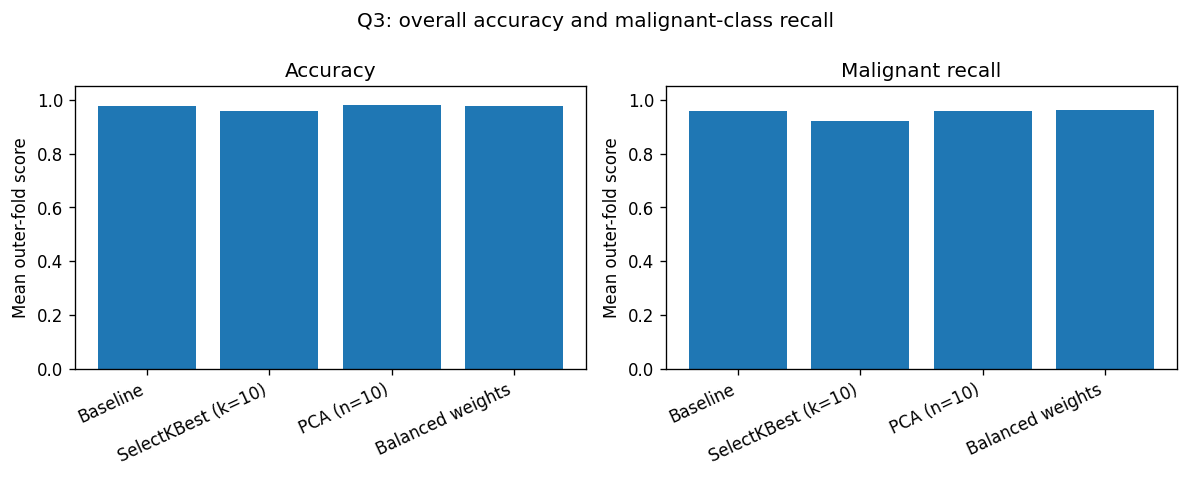

In [6]:
# Rows = actual label; columns = predicted label, ordered malignant, benign.
# With malignant treated as the clinical positive class, missed malignant
# samples are in [0, 1], and benign false alarms are in [1, 0].
for name in ['Baseline', 'Balanced weights']:
    predictions = q3_predictions[name]
    matrix = confusion_matrix(y, predictions, labels=[0, 1])
    print('\n===', name, ': pooled outer-fold predictions ===')
    print(pd.DataFrame(matrix,
                       index=['Actual malignant', 'Actual benign'],
                       columns=['Predicted malignant', 'Predicted benign']).to_string())
    print(classification_report(y, predictions, labels=[0, 1],
                                target_names=['malignant', 'benign'], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
positions = np.arange(len(q3_results))
for ax, metric in zip(axes, ['Accuracy', 'Malignant recall']):
    ax.bar(positions, q3_results[metric])
    ax.set_xticks(positions, q3_results.index, rotation=25, ha='right')
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Mean outer-fold score')
    ax.set_title(metric)
fig.suptitle('Q3: overall accuracy and malignant-class recall')
plt.tight_layout()
plt.show()

PCA gives the highest mean accuracy (0.9824); SelectKBest lowers it. Balanced weights keep accuracy at 0.9754 and reduce malignant misses from 9 to 8, with benign false alarms rising from 5 to 6. These are exploratory results on this dataset.